# 02 · Our model vs LendingClub's grade

**The question:** can a model that only sees the application rank loans by risk better than LendingClub's own grades?

**The fair-test rules**

1. **Train on the past, test on the future.** The model learns from loans issued 2007–2014 and is tested on 2015 loans it has never seen. A stricter version that learns only from loans whose outcomes were all known by December 2014 is checked further down.
2. **No peeking at the answer.** The model never sees LendingClub's grade or interest rate (the thing we compete against), or anything that happened after the loan was made.
3. **Two baselines.** LendingClub's sub-grade and its interest rate, used as risk rankings.

**How we score it:** AUC, the chance that the model rates a randomly picked defaulted loan riskier than a randomly picked repaid one. 0.5 is a coin flip, 1.0 is perfect.

**What this test does not cover**

- **60-month loans are excluded.** Only 36-month loans are used, because many 60-month loans from 2015 had not finished by the end of the data, so their outcomes are unknown.
- **Rejected applications are not here.** The data only holds loans LendingClub approved, so nothing below says how the model would treat the people LendingClub turned down.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = pd.read_parquet("data/loans_clean.parquet")
print(f"{len(df):,} loans loaded")

618,584 loans loaded


In [2]:
NUMERIC = [
    "loan_amnt", "fico", "annual_inc", "dti", "revol_bal", "revol_util", "open_acc",
    "total_acc", "delinq_2yrs", "inq_last_6mths", "pub_rec", "emp_years", "credit_history_years",
]
CATEGORICAL = ["home_ownership", "purpose"]
FEATURES = NUMERIC + CATEGORICAL
# Deliberately NOT features: grade, sub_grade, int_rate (LendingClub's answer),
# loan_status, total_pymnt, funded_amnt (what happened later), job_title (saved for the stereotype test)

train = df[df["year"] <= 2014]
test = df[df["year"] == 2015].copy()

print(f"Train: {len(train):,} loans (2007-2014), default rate {train['default'].mean():.1%}")
print(f"Test:  {len(test):,} loans (2015),      default rate {test['default'].mean():.1%}")

Train: 335,558 loans (2007-2014), default rate 13.1%
Test:  283,026 loans (2015),      default rate 14.9%


## Train two models

- **Logistic regression:** simple and easy to explain.
- **Gradient boosting:** a stronger model that learns from many small decision trees.

Both get the same preparation: fill missing numbers with the middle value, and turn categories like `purpose` into yes/no columns. Training the boosting model takes a minute or two.

In [3]:
prep = ColumnTransformer([
    ("numbers", Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC),
    ("categories", Pipeline([
        ("fill", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), CATEGORICAL),
])

models = {
    "Logistic regression": Pipeline([("prep", clone(prep)), ("model", LogisticRegression(max_iter=2000))]),
    "Gradient boosting": Pipeline([("prep", clone(prep)), ("model", HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, random_state=42))]),
}

risk = {}
for name, pipe in models.items():
    pipe.fit(train[FEATURES], train["default"])
    risk[name] = pipe.predict_proba(test[FEATURES])[:, 1]
    print(f"Trained: {name}")

Trained: Logistic regression


Trained: Gradient boosting


## The head-to-head on 2015 loans

In [4]:
SUBGRADE_ORDER = [f"{g}{n}" for g in "ABCDEFG" for n in range(1, 6)]
subgrade_rank = test["sub_grade"].map({sg: i for i, sg in enumerate(SUBGRADE_ORDER)})

scores = {name: roc_auc_score(test["default"], r) for name, r in risk.items()}
scores["LendingClub sub-grade (baseline)"] = roc_auc_score(test["default"], subgrade_rank)
scores["LendingClub interest rate (baseline)"] = roc_auc_score(test["default"], test["int_rate"])

results = pd.Series(scores, name="AUC on 2015 loans").sort_values(ascending=False).round(3).to_frame()
results

,AUC on 2015 loans
LendingClub sub-grade (baseline),0.679
LendingClub interest rate (baseline),0.678
Gradient boosting,0.669
Logistic regression,0.655


**Leak check before celebrating.** On data like this, a model that beats the platform's grade by a huge margin usually means an after-the-fact column slipped in. If your model is far above the grade, re-check the feature list before trusting it.

## Does the model know something the grade doesn't?

Two loans with the same sub-grade pay the same interest rate. If our model can still tell which of them is riskier, it adds information the grade misses. We measure AUC **inside each sub-grade** and average it, weighted by how many loans each has. 0.5 here would mean the model adds nothing beyond the grade.

Sub-grades with fewer than 200 loans in 2015 are left out of this average, because an AUC worked out from a handful of defaults is mostly noise. The cell below lists which ones are dropped.

In [5]:
# We decided BEFORE looking at 2015 results that gradient boosting is our main model.
# Picking whichever model scored best on 2015 would be peeking at the test.
BEST = "Gradient boosting"
test["model_risk"] = risk[BEST]
print("Main model:", BEST)

MIN_LOANS = 200


def within_subgrade_auc(risk_scores):
    """AUC inside each 2015 sub-grade, averaged by loan count. Also returns the sub-grades left out."""
    frame = pd.DataFrame({"sub_grade": test["sub_grade"].to_numpy(), "default": test["default"].to_numpy(),
                          "risk": np.asarray(risk_scores)})
    kept, dropped = [], []
    for sg, group in frame.groupby("sub_grade"):
        if group["default"].nunique() == 2 and len(group) >= MIN_LOANS:
            kept.append((sg, len(group), roc_auc_score(group["default"], group["risk"])))
        else:
            dropped.append((sg, len(group)))
    kept = pd.DataFrame(kept, columns=["sub_grade", "loans", "auc"])
    dropped = pd.DataFrame(dropped, columns=["sub_grade", "loans"])
    return np.average(kept["auc"], weights=kept["loans"]), kept, dropped


weighted_auc, within, dropped = within_subgrade_auc(test["model_risk"])
print(f"Average AUC inside a sub-grade: {weighted_auc:.3f}  (0.5 = adds nothing beyond the grade)")
print(f"Left out (fewer than {MIN_LOANS} loans in 2015): "
      + ", ".join(f"{r.sub_grade} ({r.loans} loans)" for r in dropped.itertuples()))
print(f"Together that is {dropped['loans'].sum():,} loans, {dropped['loans'].sum() / len(test):.2%} of the 2015 test set.")

Main model: Gradient boosting


Average AUC inside a sub-grade: 0.583  (0.5 = adds nothing beyond the grade)
Left out (fewer than 200 loans in 2015): F4 (158 loans), F5 (134 loans), G1 (95 loans), G2 (80 loans), G3 (41 loans), G4 (23 loans), G5 (6 loans)
Together that is 537 loans, 0.19% of the 2015 test set.


## The money test

**Headline: inside the same sub-grades, the half of 2015 loans our model rated safest defaulted 12.2% of the time, and the half it rated riskiest defaulted 17.6%.** (Across all 2015 loans the rate was 14.9%.)

Imagine investing in 2015. Option 1: pick a grade and buy all its loans. Option 2: pick the same grade, but only buy the half our model rates safest. Same grades, same interest rates, so any difference comes from our model.

**About the return columns.** Simple return = (total paid back − amount lent) ÷ amount lent, over the whole life of the loan. It is **not annualised**: a loan paid off after one year and one paid off after three count the same. It also ignores fees, the timing of payments and reinvesting the money, and assumes you could have bought exactly these loans. Treat the returns as **illustrative**, not as what an investor would actually have earned. The default rates are the more solid result.

In [6]:
test["simple_return"] = (test["total_pymnt"] - test["funded_amnt"]) / test["funded_amnt"]
# Inside each sub-grade, the "safest half" is every loan at or below that sub-grade's median model risk
test["safest_half"] = test.groupby("sub_grade")["model_risk"].transform(lambda s: s <= s.median())

def summarise(frame):
    out = frame.groupby("grade").agg(
        loans=("default", "size"),
        default_rate_pct=("default", "mean"),
        simple_return_pct=("simple_return", "mean"),
    )
    out[["default_rate_pct", "simple_return_pct"]] *= 100
    return out

all_loans = summarise(test)
safest = summarise(test[test["safest_half"]])
riskiest = summarise(test[~test["safest_half"]])

money = pd.DataFrame({
    "Default %: all loans": all_loans["default_rate_pct"],
    "Default %: safest half": safest["default_rate_pct"],
    "Default %: riskiest half": riskiest["default_rate_pct"],
    "Return %: all loans": all_loans["simple_return_pct"],
    "Return %: safest half": safest["simple_return_pct"],
})
money.loc["All grades"] = [
    test["default"].mean() * 100,
    test.loc[test["safest_half"], "default"].mean() * 100,
    test.loc[~test["safest_half"], "default"].mean() * 100,
    test["simple_return"].mean() * 100,
    test.loc[test["safest_half"], "simple_return"].mean() * 100,
]
money = money.round(1)
money

,Default %: all loans,Default %: safest half,Default %: riskiest half,Return %: all loans,Return %: safest half
grade,,,,,
A,5.4,4.0,6.8,6.7,7.2
B,11.9,9.5,14.3,7.3,8.2
C,19.4,16.0,22.9,6.6,8.0
D,26.2,22.1,30.4,5.5,7.4
E,32.8,28.8,36.9,3.2,5.5
F,42.4,38.3,46.5,0.3,2.8
G,46.1,39.5,52.9,-3.4,3.7
All grades,14.9,12.2,17.6,6.6,7.7


In [7]:
safe_rate = test.loc[test["safest_half"], "default"].mean()
risky_rate = test.loc[~test["safest_half"], "default"].mean()
print(f"Safest half defaulted {safe_rate:.1%}, riskiest half {risky_rate:.1%} "
      f"(all 2015 loans: {test['default'].mean():.1%})")

Safest half defaulted 12.2%, riskiest half 17.6% (all 2015 loans: 14.9%)


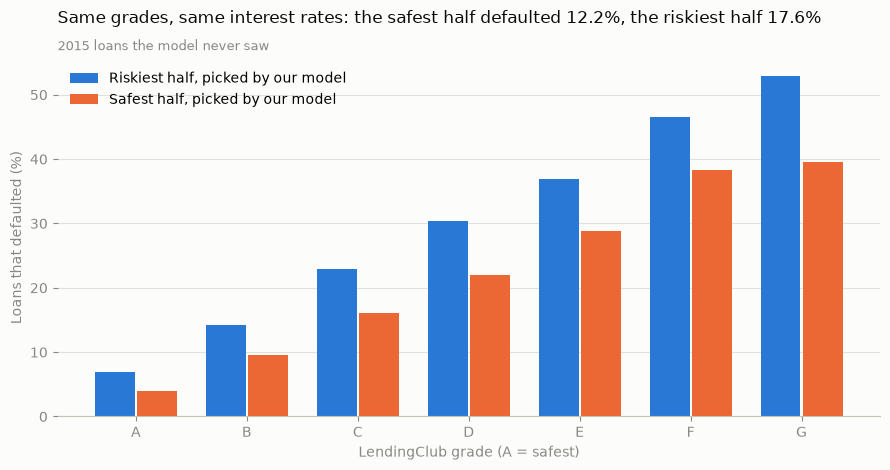

In [8]:
grades = list(all_loans.index)
x = np.arange(len(grades))
width = 0.36
BLUE, ORANGE = "#2a78d6", "#eb6834"   # validated colour pair
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

overall_risky = money.loc["All grades", "Default %: riskiest half"]
overall_safe = money.loc["All grades", "Default %: safest half"]

fig, ax = plt.subplots(figsize=(9, 4.8), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
ax.bar(x - width / 2 - 0.01, riskiest["default_rate_pct"], width, color=BLUE, label="Riskiest half, picked by our model")
ax.bar(x + width / 2 + 0.01, safest["default_rate_pct"], width, color=ORANGE, label="Safest half, picked by our model")

ax.set_xticks(x, grades)
ax.set_xlabel("LendingClub grade (A = safest)", color=MUTED)
ax.set_ylabel("Loans that defaulted (%)", color=MUTED)
ax.set_title(
    f"Same grades, same interest rates: the safest half defaulted {overall_safe:.1f}%, the riskiest half {overall_risky:.1f}%",
    loc="left", color=INK, fontsize=12, pad=26,
)
ax.text(0, 1.025, "2015 loans the model never saw", transform=ax.transAxes, color=MUTED, fontsize=9)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.tick_params(colors=MUTED)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()

Path("outputs").mkdir(exist_ok=True)
fig.savefig("outputs/money_test.png", dpi=200)
plt.show()

## No-hindsight check: learn only from loans finished by December 2014

**Why this matters.** The main model learns from loans issued 2007–2014, and we kept only loans whose ending we know. For a loan issued in 2013 or 2014, we only know how it ended because the data runs to 2018: a 36-month loan made in mid-2014 wasn't finished until mid-2017. Someone choosing loans at the start of 2015 couldn't have known those endings yet. So the main model has a little hindsight built in: some of what it learned from hadn't happened yet when the 2015 loans were made.

To check that this hindsight isn't what makes the model look good, we retrain **exactly the same model** on 2007–2011 loans only. Every 36-month loan from those years had reached its end date by December 2014, so everything this version learns from was already known before the first 2015 loan was issued. It has far less data to learn from, so a small drop is expected. If it stays close to the main version, hindsight isn't doing the work.

**Same-size check.** The no-hindsight version also has far fewer loans to learn from, because LendingClub was much smaller before 2012. To tell the two apart, a third version learns from a random sample of 2007–2014 loans, cut to exactly the same number as the no-hindsight version. It has the hindsight but not the data, so:

- if it scores about as low as the no-hindsight version, the drop is down to **having less data**;
- if it scores close to the main version, the drop is down to **hindsight**.

In [9]:
train_nh = df[df["year"] <= 2011]
model_nh = clone(models[BEST])            # same settings, untrained
model_nh.fit(train_nh[FEATURES], train_nh["default"])
risk_nh = model_nh.predict_proba(test[FEATURES])[:, 1]
print(f"No-hindsight training set: {len(train_nh):,} loans (2007-2011), default rate {train_nh['default'].mean():.1%}")

# Same-size check: 2007-2014 loans (with hindsight), cut down at random to the no-hindsight sample size
train_small = train.sample(n=len(train_nh), random_state=42)
model_small = clone(models[BEST])
model_small.fit(train_small[FEATURES], train_small["default"])
risk_small = model_small.predict_proba(test[FEATURES])[:, 1]
print(f"Same-size training set:    {len(train_small):,} loans (random sample of 2007-2014), default rate {train_small['default'].mean():.1%}")


def half_default_rates(risk_scores):
    """Default rate of the safest and riskiest half inside each sub-grade (split at the sub-grade's median risk)."""
    r = pd.Series(np.asarray(risk_scores), index=test.index)
    safe = r.groupby(test["sub_grade"]).transform(lambda s: s <= s.median())
    return test.loc[safe, "default"].mean(), test.loc[~safe, "default"].mean()


def scorecard(risk_scores, train_frame, years):
    within_w, _, _ = within_subgrade_auc(risk_scores)
    safe, risky = half_default_rates(risk_scores)
    return {
        "Training years": years,
        "Training loans": f"{len(train_frame):,}",
        "2015 AUC": f"{roc_auc_score(test['default'], risk_scores):.3f}",
        "Within-sub-grade AUC": f"{within_w:.3f}",
        "Safest half default %": f"{safe * 100:.1f}",
        "Riskiest half default %": f"{risky * 100:.1f}",
        "Gap (points)": f"{(risky - safe) * 100:.1f}",
    }


comparison = pd.DataFrame({
    "Main version": scorecard(test["model_risk"], train, "2007-2014"),
    "No-hindsight version": scorecard(risk_nh, train_nh, "2007-2011"),
    "Same-size check": scorecard(risk_small, train_small, "2007-2014 (random sample)"),
})
comparison.to_csv("outputs/no_hindsight_comparison.csv")
print(f"For reference, LendingClub's sub-grade alone scores AUC {scores['LendingClub sub-grade (baseline)']:.3f} on 2015 loans.")
comparison

No-hindsight training set: 29,096 loans (2007-2011), default rate 11.1%


Same-size training set:    29,096 loans (random sample of 2007-2014), default rate 12.9%


For reference, LendingClub's sub-grade alone scores AUC 0.679 on 2015 loans.


,Main version,No-hindsight version,Same-size check
Training years,2007-2014,2007-2011,2007-2014 (random sample)
Training loans,"335,558","29,096","29,096"
2015 AUC,0.669,0.631,0.650
Within-sub-grade AUC,0.583,0.546,0.567
Safest half default %,12.2,13.6,12.7
Riskiest half default %,17.6,16.2,17.1
Gap (points),5.4,2.7,4.4


**What the comparison shows.** Without hindsight the model is clearly weaker. Its 2015 AUC falls from 0.669 to 0.631, its within-sub-grade AUC from 0.583 to 0.546, and the gap between the safest and riskiest halves shrinks from 5.4 to 2.7 points (13.6% vs 16.2%, against 12.2% vs 17.6%). It still finds something the grade misses: 0.546 is above 0.5, and its safest half still defaults less than its riskiest half.

**The same-size check splits that drop roughly in half.** With the same 29,096 loans but drawn from all of 2007–2014, the model scores 0.650 overall and 0.567 within sub-grades, with a 4.4-point gap (12.7% vs 17.1%).

- **Having less data** costs about 0.019 of AUC (0.669 → 0.650), 0.016 within sub-grades and 1.0 point of the gap.
- **Missing the 2012–2014 loans** costs about another 0.019 (0.650 → 0.631), 0.021 within sub-grades and 1.7 points of the gap.

So a bit more than half of the within-grade edge we lose comes from not having the most recent loans. We can't tell how much of that is hindsight itself and how much is that 2012–2014 loans simply look more like 2015 loans. Either way, a lender at the start of 2015 couldn't have used how those loans turned out.

Read the main version's numbers as the best case and the no-hindsight version's as the cautious case. The same-size check is a single random sample, so treat its numbers as approximate.

## Grade + our model: does the model add to the grade?

The head-to-head above asks whether our model can **replace** LendingClub's grade. A lender would more likely ask whether it can **add** to it. So we train a second boosting model on the same application data **plus LendingClub's sub-grade** (as its position from A1 = 0 to G5 = 34), and compare its 2015 AUC with the sub-grade on its own. The interest rate is still left out.

This is an extra analysis, not the main model we committed to in advance.

**How sure are we?** We resample the 2015 loans with replacement 1,000 times, work out both AUCs on each resample, and take the middle 95% of the differences. If that interval doesn't include 0, the gain isn't just luck in which loans happened to land in the test year. This only covers that kind of luck. It doesn't cover what would happen if the model were retrained with different settings.

In [10]:
SG_RANK = {sg: i for i, sg in enumerate(SUBGRADE_ORDER)}
NUMERIC_PLUS = NUMERIC + ["subgrade_rank"]


def with_grade(frame):
    return frame[FEATURES].assign(subgrade_rank=frame["sub_grade"].map(SG_RANK))


prep_plus = ColumnTransformer([
    ("numbers", Pipeline([("fill", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC_PLUS),
    ("categories", Pipeline([
        ("fill", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), CATEGORICAL),
])
model_plus = Pipeline([("prep", prep_plus), ("model", HistGradientBoostingClassifier(
    max_iter=300, learning_rate=0.05, random_state=42))])
model_plus.fit(with_grade(train), train["default"])
risk_plus = model_plus.predict_proba(with_grade(test))[:, 1]

y = test["default"].to_numpy()
grade_only = subgrade_rank.to_numpy()
auc_plus = roc_auc_score(y, risk_plus)
auc_grade = roc_auc_score(y, grade_only)

rng = np.random.default_rng(42)
diffs = np.empty(1000)
for b in range(len(diffs)):
    idx = rng.integers(0, len(y), len(y))
    diffs[b] = roc_auc_score(y[idx], risk_plus[idx]) - roc_auc_score(y[idx], grade_only[idx])
low, high = np.percentile(diffs, [2.5, 97.5])

grade_plus = pd.Series({
    "Sub-grade alone": f"{auc_grade:.3f}",
    "Grade + our model": f"{auc_plus:.3f}",
    "Difference (95% interval)": f"{auc_plus - auc_grade:+.3f} ({low:+.3f} to {high:+.3f})",
}, name="2015 AUC").to_frame()
pd.DataFrame({"value": [auc_grade, auc_plus, auc_plus - auc_grade, low, high]},
             index=["auc_subgrade_alone", "auc_grade_plus_model", "difference", "ci95_low", "ci95_high"]
             ).to_csv("outputs/grade_plus_model.csv")
grade_plus

,2015 AUC
Sub-grade alone,0.679
Grade + our model,0.693
Difference (95% interval),+0.015 (+0.013 to +0.016)


**Result.** With the sub-grade added, the model scores **0.693** on 2015 loans against **0.679** for the sub-grade alone, a gain of **+0.015** (95% interval +0.013 to +0.016; the gain is worked out before rounding). The interval is well clear of 0, so our model adds real information on top of LendingClub's grade even though it can't beat the grade on its own. That is the fairest way to sum up the project: the model is a useful second opinion on the grade, not a replacement for it.

## Where the model fails

Judges score honesty. These are 2015 loans our model rated among the very safest that still defaulted. Look at them and write one sentence in the README about why the model missed them.

In [11]:
surprises = test[test["default"] == 1].nsmallest(5, "model_risk")
surprises[["sub_grade", "model_risk", "loan_amnt", "annual_inc", "fico", "dti", "purpose", "emp_years"]].round(3)

,sub_grade,model_risk,loan_amnt,annual_inc,fico,dti,purpose,emp_years
142556,A2,0.015,5000.0,82450.0,822.0,0.64,home_improvement,10.0
48945,B3,0.016,15000.0,95000.0,807.0,2.44,home_improvement,10.0
224414,A1,0.016,16000.0,300000.0,822.0,6.93,credit_card,5.0
272734,A1,0.016,9900.0,142000.0,792.0,13.04,debt_consolidation,9.0
48189,A2,0.017,15000.0,92000.0,812.0,0.64,home_improvement,10.0


## Save what the demo and later notebooks need

- the trained model
- each sub-grade's historical default rate (kept for reference; the "deserved grade" below no longer uses it)
- the 2015 test loans with the model's risk score

The new results from this notebook go in `outputs/`: the no-hindsight comparison, the grade + model result, and the risk cut-offs for the deserved grade.

In [12]:
Path("models").mkdir(exist_ok=True)
joblib.dump({"model": models[BEST], "features": FEATURES, "name": BEST}, "models/default_model.joblib")

subgrade_default = (
    train.groupby("sub_grade")["default"].mean().reindex(SUBGRADE_ORDER).dropna().rename("default_rate")
)
subgrade_default.to_csv("models/subgrade_default_rates.csv")

test.to_parquet("data/test_2015_scored.parquet", index=False)
results.to_csv("outputs/auc_results.csv")
money.to_csv("outputs/money_test.csv")
print("Saved model, sub-grade default rates, scored 2015 loans and result tables.")

Saved model, sub-grade default rates, scored 2015 loans and result tables.


## The grade each loan "deserves"

We turn the model's risk score into a sub-grade by **rank**: line up all 2015 loans from safest to riskiest by our model. If LendingClub put 3% of 2015 loans in A1, our safest 3% get A1; if the next 4% were A2, our next 4% get A2, and so on up to G5.

**Why rank, not the closest default rate.** The old version gave each loan the sub-grade whose 2007–2014 default rate was closest to the model's probability. That has two problems:

1. The historical default rates aren't in order, and they bunch together from D to G. D3 loans defaulted less often than D2, G2 less often than G1, and everything from D1 to F2 sits between 20% and 27%. So a tiny change in the model's risk could jump several sub-grades. In the table below, the old mapping put about 4% of 2015 loans in F or G, when LendingClub put under 1% there, and it gave sub-grades like C4 and D2–D4 only about half to two-thirds of the loans LendingClub put there.
2. The model's average risk for 2015 loans is 13.3%, but 14.9% of them actually defaulted, because 2015 loans defaulted more often than the 2007–2014 loans the model learned from. A probability learned from history doesn't line up with a 2015 grade.

The rank version uses exactly the same mix of grades LendingClub issued in 2015. So a difference between a loan's real grade and its deserved grade is only about **which** loans get which grade, not the model using a different scale. It uses only the 2015 applications, not how those loans ended, so it doesn't peek at the answer.

In [13]:
share_2015 = test["sub_grade"].value_counts(normalize=True).reindex(SUBGRADE_ORDER).fillna(0)
cum_share = share_2015.cumsum().to_numpy()
risk_pct = test["model_risk"].rank(method="first", pct=True).to_numpy()
pos = np.minimum(np.searchsorted(cum_share, risk_pct, side="left"), len(SUBGRADE_ORDER) - 1)
deserved = pd.Series(np.array(SUBGRADE_ORDER)[pos], index=test.index)

# Risk cut-offs, so a new applicant's score can be turned into a sub-grade without the 2015 data
cutoffs = (test["model_risk"].groupby(deserved).max().reindex(SUBGRADE_ORDER)
           .rename("risk_up_to").to_frame())
cutoffs.insert(0, "share_of_2015_loans_pct", (share_2015 * 100).round(2))
cutoffs.to_csv("outputs/deserved_subgrade_cutoffs.csv")


def deserved_subgrade(probability):
    # First sub-grade whose risk cut-off is at or above this probability
    ok = cutoffs.index[cutoffs["risk_up_to"] >= probability]
    return ok[0] if len(ok) else SUBGRADE_ORDER[-1]


# Old mapping, for comparison: the sub-grade with the closest 2007-2014 default rate
rates = subgrade_default.to_numpy()
old_deserved = pd.Series(subgrade_default.index[np.abs(rates[None, :] - test["model_risk"].to_numpy()[:, None]).argmin(axis=1)],
                         index=test.index)

mix = pd.DataFrame({
    "LendingClub 2015 %": share_2015 * 100,
    "Old mapping %": old_deserved.value_counts(normalize=True).reindex(SUBGRADE_ORDER).fillna(0) * 100,
    "Rank-based %": deserved.value_counts(normalize=True).reindex(SUBGRADE_ORDER).fillna(0) * 100,
}).round(1)
print(f"Loans whose deserved sub-grade matches their real one: {(deserved == test['sub_grade']).mean():.1%}")
mix

Loans whose deserved sub-grade matches their real one: 10.4%


,LendingClub 2015 %,Old mapping %,Rank-based %
A1,4.4,3.6,4.4
A2,4.1,3.0,4.1
A3,3.8,3.7,3.8
A4,5.3,6.7,5.3
A5,7.2,6.6,7.2
B1,6.3,5.5,6.3
B2,6.5,7.0,6.5
B3,6.5,6.8,6.5
B4,6.4,7.7,6.4
B5,6.8,7.9,6.8


In [14]:
example = test.iloc[0]
print(f"Example loan: graded {example['sub_grade']}, model risk {example['model_risk']:.1%}, "
      f"which ranks like a {deserved_subgrade(example['model_risk'])} loan")

Example loan: graded C4, model risk 10.5%, which ranks like a B3 loan


## Honest notes

- **Within-sub-grade AUC leaves out the rarest sub-grades.** F4, F5 and G1–G5 each had fewer than 200 loans in 2015, so they are dropped. That is 537 loans, 0.19% of the test set, so the 0.583 average covers sub-grades A1 to F3.
- **Only 36-month loans.** 60-month loans are excluded, because many from 2015 hadn't finished by the end of the data.
- **Only approved loans.** Rejected applications aren't in the data, so these results only say how the model ranks people LendingClub had already approved.
- **Returns are rough.** The return figures are simple (total paid back ÷ amount lent), not annualised, and ignore fees, timing and reinvestment. They are illustrative; the default rates are the solid result.
- **Some hindsight in the main model.** It learned from 2012–2014 loans whose endings weren't known until after 2015 began. Without them the edge roughly halves. The same-size check suggests about half of that drop is from having less data and about half from missing the most recent loans.
- **What we committed to in advance is unchanged.** Gradient boosting on the application data alone is still the main model. The no-hindsight and grade + model versions are extra checks.